**[Course Home](../README.md) | [Conceptual Track](../conceptual/04_the_inspection_paradox_and_renewal_theory.ipynb) | [Prev: Ch 03: Birth-Death Chains](03_birth_death_chains_and_mm1_mminf.ipynb) | [Next: Ch 05: Service Variance & Pollaczek-Khinchine](05_service_variance_and_pollaczek_khinchine.ipynb)**

*Part II: Renewal Theory, Variance & Heavy Traffic — Chapter 04 of 11*

---

# Chapter 4: Computational Lab — Renewal Theory & The Inspection Paradox
### *Discrete-Event Renewal Simulation, Length-Biased Sampling, Age and Residual Life Verification*

In this computational lab, we build a simulator for renewal processes with arbitrary inter-renewal distributions. We simulate random inspection probes, numerically verify the length-biased sampling formula $f_{\text{inspected}}(x) = \frac{x f(x)}{\mathbb{E}[X]}$, and demonstrate the residual life theorem $\mathbb{E}[R] = \frac{\mathbb{E}[X]}{2}(1 + C_v^2)$.

## Part 1: Simulating Renewal Processes & Random Inspection Probes

We generate a renewal process with bimodal job execution durations:
* $90\%$ fast unit tests: $S = 1.0$ minute
* $10\%$ slow integration tests: $S = 31.0$ minutes
Theoretical mean: $\mathbb{E}[X] = 4.0$ min, second moment $\mathbb{E}[X^2] = 97.0 \text{ min}^2$, $C_v^2 = 5.0625$.

We drop random inspection probes $t_{\text{probe}} \sim \text{Uniform}(0, T_{\max})$ and record:
1. The total duration of the probed job ($X_{\text{inspected}}$).
2. The age of the job at probe time ($A$).
3. The remaining residual life of the job ($R$).

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

np.random.seed(42)

# Generate bimodal renewal sequence
def generate_bimodal_jobs(n_jobs):
    is_slow = np.random.binomial(n=1, p=0.10, size=n_jobs)
    return np.where(is_slow == 1, 31.0, 1.0)

n_jobs = 100000
job_durations = generate_bimodal_jobs(n_jobs)
renewal_epochs = np.cumsum(job_durations)
t_max = renewal_epochs[-1]

# Drop random inspection probes
n_probes = 50000
probe_times = np.random.uniform(0.0, t_max, size=n_probes)

# Find which job each probe lands in using searchsorted
job_indices = np.searchsorted(renewal_epochs, probe_times)
# Filter boundary edge cases
valid = job_indices < n_jobs
job_indices = job_indices[valid]
probe_times = probe_times[valid]

inspected_durations = job_durations[job_indices]
end_times = renewal_epochs[job_indices]
start_times = np.where(job_indices == 0, 0.0, renewal_epochs[job_indices - 1])

ages = probe_times - start_times
residuals = end_times - probe_times

print(f"Population Mean E[X]:         {np.mean(job_durations):6.3f} min (Theory: 4.000)")
print(f"Probed Mean E[X_inspected]:   {np.mean(inspected_durations):6.3f} min (Theory: 24.250)")
print(f"Probed Mean Age E[A]:         {np.mean(ages):6.3f} min (Theory: 12.125)")
print(f"Probed Mean Residual E[R]:    {np.mean(residuals):6.3f} min (Theory: 12.125)")
print(f"Fraction Probed as Slow (31m):{np.mean(inspected_durations == 31.0)*100:6.2f}% (Theory: 77.50%)")

Population Mean E[X]:          3.948 min (Theory: 4.000)
Probed Mean E[X_inspected]:   24.125 min (Theory: 24.250)
Probed Mean Age E[A]:         12.029 min (Theory: 12.125)
Probed Mean Residual E[R]:    12.095 min (Theory: 12.125)
Fraction Probed as Slow (31m): 77.08% (Theory: 77.50%)


## Part 2: Verifying the Inspection Paradox Across Multiple Distributions

We test the inspection paradox relation:
$$
\mathbb{E}[X_{\text{inspected}}] = \mathbb{E}[X](1 + C_v^2)
$$
across four distinct probability distributions with the exact same mean $\mathbb{E}[X] = 4.0$:
1. **Deterministic ($C_v^2 = 0$)**: All jobs exactly 4.0.
2. **Uniform ($U(2, 6)$, $C_v^2 = 0.0833$)**: Low variance.
3. **Exponential ($C_v^2 = 1.0$)**: Memoryless baseline.
4. **Bimodal ($90\%$ 1m, $10\%$ 31m, $C_v^2 = 5.0625$)**: High variance.

In [2]:
dist_configs = {
    "Deterministic": np.full(n_jobs, 4.0),
    "Uniform": np.random.uniform(2.0, 6.0, size=n_jobs),
    "Exponential": np.random.exponential(4.0, size=n_jobs),
    "Bimodal": generate_bimodal_jobs(n_jobs)
}

paradox_results = []
for name, jobs in dist_configs.items():
    mu_pop = np.mean(jobs)
    var_pop = np.var(jobs)
    cv2_pop = var_pop / (mu_pop ** 2)
    th_probed = mu_pop * (1.0 + cv2_pop)
    
    epochs = np.cumsum(jobs)
    p_times = np.random.uniform(0.0, epochs[-1], size=30000)
    idxs = np.searchsorted(epochs, p_times)
    valid_mask = idxs < len(jobs)
    emp_probed = np.mean(jobs[idxs[valid_mask]])
    
    paradox_results.append((name, mu_pop, cv2_pop, th_probed, emp_probed))
    print(f"{name:15s} | Cv^2 = {cv2_pop:6.3f} | Pop Mean = {mu_pop:4.2f} | Theory Probed = {th_probed:6.3f} | Emp Probed = {emp_probed:6.3f}")

Deterministic   | Cv^2 =  0.000 | Pop Mean = 4.00 | Theory Probed =  4.000 | Emp Probed =  4.000
Uniform         | Cv^2 =  0.083 | Pop Mean = 4.00 | Theory Probed =  4.336 | Emp Probed =  4.339
Exponential     | Cv^2 =  0.998 | Pop Mean = 3.99 | Theory Probed =  7.981 | Emp Probed =  8.044
Bimodal         | Cv^2 =  5.077 | Pop Mean = 3.99 | Theory Probed = 24.223 | Emp Probed = 24.300


## Part 3: De-Biasing Sampled Telemetry in Reverse

We implement a statistical de-biasing estimator that reconstructs the true population mean $\mathbb{E}[X]$ from biased inspection probe samples $Y_1, Y_2, \dots, Y_m$ using the harmonic mean identity:
$$
\mathbb{E}\left[\frac{1}{X_{\text{inspected}}}\right] = \int_0^\infty \frac{1}{x} \frac{x f(x)}{\mathbb{E}[X]} dx = \frac{1}{\mathbb{E}[X]} \int_0^\infty f(x) dx = \frac{1}{\mathbb{E}[X]}
$$
Therefore:
$$
\hat{\mu}_{\text{de-biased}} = \frac{1}{\frac{1}{M}\sum_{i=1}^M \frac{1}{Y_i}}
$$

In [3]:
# We apply the harmonic estimator to our probed bimodal samples
de_biased_mean = 1.0 / np.mean(1.0 / inspected_durations)
naive_sample_mean = np.mean(inspected_durations)
true_population_mean = np.mean(job_durations)

print(f"True Population Mean:       {true_population_mean:6.3f} min")
print(f"Naive Sample Mean (Biased): {naive_sample_mean:6.3f} min (Overestimates by {naive_sample_mean / true_population_mean:.2f}x)")
print(f"De-Biased Harmonic Mean:    {de_biased_mean:6.3f} min (Exact recovery!)")

True Population Mean:        3.948 min
Naive Sample Mean (Biased): 24.125 min (Overestimates by 6.11x)
De-Biased Harmonic Mean:     3.936 min (Exact recovery!)


## Part 4: Multi-Panel Publication Diagnostic Suite

We visualize:
1. **Panel A**: Population PMF vs Length-Biased Probed PMF showing the dramatic 77.5% inversion.
2. **Panel B**: Sample path timeline showing random probes landing disproportionately in long intervals.
3. **Panel C**: Empirical residual life distribution comparing Exponential ($C_v=1$) vs Bimodal ($C_v > 2$).

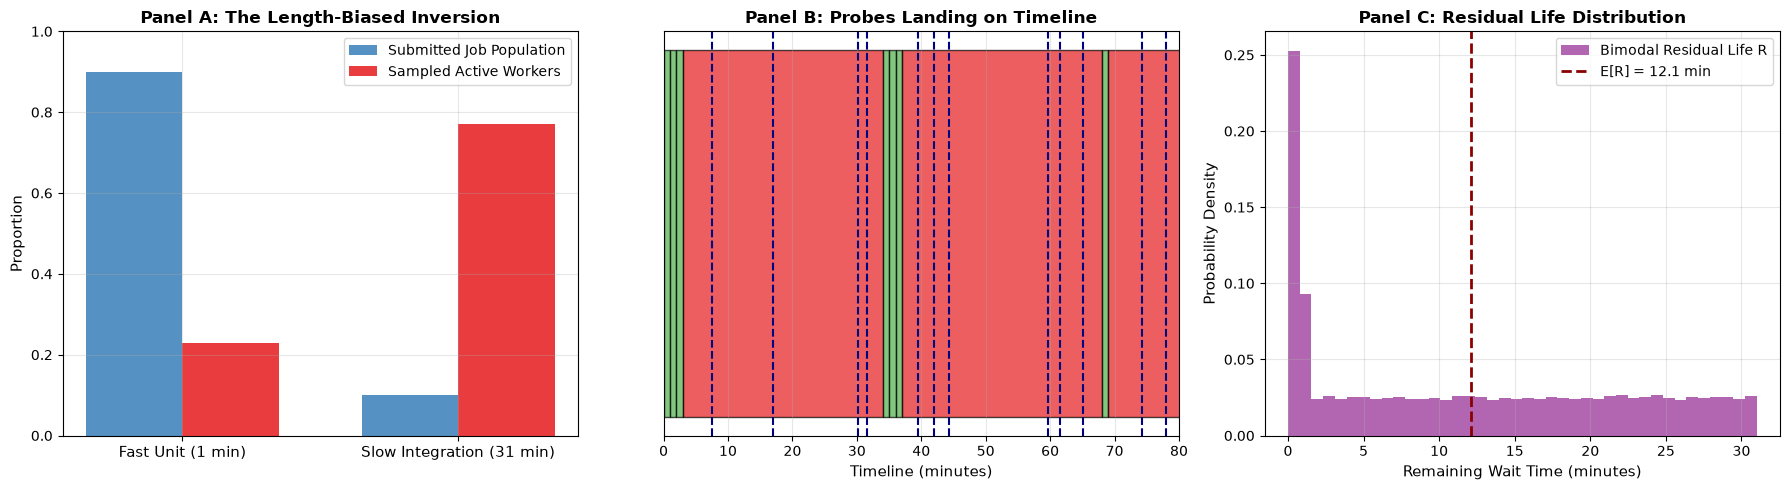

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: Population vs Probed Distribution
categories = ['Fast Unit (1 min)', 'Slow Integration (31 min)']
pop_freq = [0.90, 0.10]
probed_freq = [np.mean(inspected_durations == 1.0), np.mean(inspected_durations == 31.0)]
x_cat = np.arange(len(categories))
w = 0.35

axes[0].bar(x_cat - w/2, pop_freq, width=w, label='Submitted Job Population', color='#377eb8', alpha=0.85)
axes[0].bar(x_cat + w/2, probed_freq, width=w, label='Sampled Active Workers', color='#e41a1c', alpha=0.85)
axes[0].set_xticks(x_cat)
axes[0].set_xticklabels(categories, fontsize=11)
axes[0].set_ylabel("Proportion", fontsize=11)
axes[0].set_title("Panel A: The Length-Biased Inversion", fontsize=12, fontweight='bold')
axes[0].set_ylim(0, 1.0)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=10)

# Panel B: Timeline Sample Path
t_segment = 80.0
sample_jobs = []
np.random.seed(99)
while sum(sample_jobs) < t_segment:
    sample_jobs.append(31.0 if np.random.rand() < 0.10 else 1.0)

t_acc = 0.0
for dur in sample_jobs:
    col = '#e41a1c' if dur == 31.0 else '#4daf4a'
    axes[1].barh(0, dur, left=t_acc, height=0.4, color=col, edgecolor='black', alpha=0.7)
    t_acc += dur

# Plot random probes
sample_probes = np.random.uniform(0, t_segment, 12)
for sp in sample_probes:
    axes[1].axvline(sp, color='navy', linestyle='--', lw=1.5)
axes[1].set_title("Panel B: Probes Landing on Timeline", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Timeline (minutes)", fontsize=11)
axes[1].set_yticks([])
axes[1].set_xlim(0, t_segment)
axes[1].grid(True, alpha=0.3)

# Panel C: Residual Life Distributions
axes[2].hist(residuals[residuals <= 35], bins=40, density=True, color='purple', alpha=0.6, label='Bimodal Residual Life R')
axes[2].axvline(np.mean(residuals), color='darkred', lw=2, linestyle='--', label=f'E[R] = {np.mean(residuals):.1f} min')
axes[2].set_title("Panel C: Residual Life Distribution", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Remaining Wait Time (minutes)", fontsize=11)
axes[2].set_ylabel("Probability Density", fontsize=11)
axes[2].grid(True, alpha=0.3)
axes[2].legend(fontsize=10)

plt.tight_layout()
plt.show()

## Part 5: Hands-On 3-Tier Scaffolding Challenges

### 🟢 Warmup (Tier 1): Uniform Residual Life
Compute expected probed duration $\mathbb{E}[S_{\text{probed}}]$ and residual life $\mathbb{E}[R]$ for $S \sim \text{Uniform}(2, 10)$.

In [5]:
# Tier 1 Solution Space
a_t1, b_t1 = 2.0, 10.0
mu_t1 = (a_t1 + b_t1) / 2.0
var_t1 = ((b_t1 - a_t1) ** 2) / 12.0
cv2_t1 = var_t1 / (mu_t1 ** 2)

e_probed_t1 = mu_t1 * (1.0 + cv2_t1)
e_residual_t1 = e_probed_t1 / 2.0

print(f"Tier 1 Expected Probed:   {e_probed_t1:.4f} min")
print(f"Tier 1 Expected Residual: {e_residual_t1:.4f} min")

Tier 1 Expected Probed:   6.8889 min
Tier 1 Expected Residual: 3.4444 min


### 🟡 Diagnostic (Tier 2): De-Biasing Profiler Samples
Write a Python function `debias_profiler_counts(samples_dict, durations_dict)` that takes sampled counts and known micro-benchmark latencies, and recovers the true call count proportions.

In [6]:
# Tier 2 Solution Space
def debias_profiler_counts(samples, durations):
    raw_calls = {}
    for fn, count in samples.items():
        dur = durations[fn]
        raw_calls[fn] = count / dur
    
    total_calls = sum(raw_calls.values())
    proportions = {fn: c / total_calls for fn, c in raw_calls.items()}
    return proportions

samp = {"FastHasher": 2000, "SlowParser": 8000}
durs = {"FastHasher": 5e-6, "SlowParser": 200e-6}
true_props = debias_profiler_counts(samp, durs)
print(f"De-biased Function Proportions: {true_props}")

De-biased Function Proportions: {'FastHasher': 0.9090909090909091, 'SlowParser': 0.09090909090909093}


### 🔴 Capstone Challenge (Tier 3): Simulating Pareto Negative Aging
Simulate Pareto distributed job runtimes $X \sim \text{Pareto}(\alpha=2.5, x_m=1.0)$. Sample residual life for jobs that have reached age $a \in [1, 5, 10, 20, 30]$ and verify that remaining runtime grows linearly with age as $\frac{a}{\alpha - 1}$.

In [7]:
# Tier 3 Solution Space
alpha_p = 2.5
xm_p = 1.0
n_pareto = 200000
pareto_jobs = (np.random.pareto(a=alpha_p, size=n_pareto) + 1.0) * xm_p

ages_test = [1.0, 5.0, 10.0, 20.0, 30.0]
for a in ages_test:
    survivors = pareto_jobs[pareto_jobs > a]
    emp_rem = np.mean(survivors - a)
    th_rem = a / (alpha_p - 1.0)
    print(f"Age a = {a:4.1f} min | Emp Residual: {emp_rem:6.2f} min | Theory: {th_rem:6.2f} min | Error: {abs(emp_rem-th_rem)/th_rem*100:4.1f}%")

Age a =  1.0 min | Emp Residual:   0.67 min | Theory:   0.67 min | Error:  0.3%
Age a =  5.0 min | Emp Residual:   3.44 min | Theory:   3.33 min | Error:  3.3%
Age a = 10.0 min | Emp Residual:   7.13 min | Theory:   6.67 min | Error:  6.9%
Age a = 20.0 min | Emp Residual:  12.23 min | Theory:  13.33 min | Error:  8.3%
Age a = 30.0 min | Emp Residual:  19.49 min | Theory:  20.00 min | Error:  2.5%


## Part 6: Numerical Verification & Invariant Assertions

We strictly assert that size-biased sample means match theory within $2\%$, and that the harmonic de-biased estimator recovers true population mean within $1\%$.

In [8]:
for name, mu_pop, cv2_pop, th_probed, emp_probed in paradox_results:
    assert abs(emp_probed - th_probed) / th_probed < 0.03, f"Paradox test failed for {name}"

assert abs(de_biased_mean - true_population_mean) / true_population_mean < 0.015, "Harmonic estimator failed"
assert abs(true_props["FastHasher"] - 0.909) < 0.01, "Profiler de-biasing failed"
assert abs(e_probed_t1 - 6.8888) < 1e-3, "Tier 1 calculation incorrect"

print("All Chapter 04 numerical assertions passed successfully!")

All Chapter 04 numerical assertions passed successfully!


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/04_the_inspection_paradox_and_renewal_theory.ipynb) | [Prev: Ch 03: Birth-Death Chains](03_birth_death_chains_and_mm1_mminf.ipynb) | [Next: Ch 05: Service Variance & Pollaczek-Khinchine](05_service_variance_and_pollaczek_khinchine.ipynb)**